# ДЗ до теми 12: машинний переклад з механізмом уваги

Студент: Фарід Джафарлі

Набір даних Helsinki-NLP/europarl містить речення з засідань Європейського парламенту, перекладені кількома мовами. Задача: навчити модель seq2seq з механізмом уваги перекладати речення з однієї мови на іншу і подивитися, як працює увага.

## 1. Імпорт бібліотек

In [1]:
import json
import random
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spacy
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader
from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')
print('Пристрій:', DEVICE)

Пристрій: mps


## 2. Вибір пари мов

Я перекладаю з німецької на англійську. Обидві мови підтримує spaCy. До того ж у німецькій інший порядок слів (дієслово часто стоїть у кінці речення), тому на картах уваги буде видно, як модель шукає потрібне слово не лише на тому самому місці.

In [2]:
SRC_LANG, TRG_LANG = 'de', 'en'

## 3. Завантаження і підготовка даних

У парі de-en майже 2 мільйони речень. Щоб навчання тривало розумний час, я беру підмножину: речення довжиною від 3 до 20 слів з обох боків, без повторів, разом 103 тисячі пар. З них 100 тисяч для навчання, 2 тисячі для валідації і 1 тисяча тестових речень для прикладів перекладу.

In [3]:
N_TRAIN, N_VAL, N_TEST = 100_000, 2_000, 1_000

raw = load_dataset('Helsinki-NLP/europarl', f'{SRC_LANG}-{TRG_LANG}', split='train')
print('Пар речень у наборі:', len(raw))
sample = raw.shuffle(seed=SEED).select(range(400_000))['translation']

pairs, seen = [], set()
for ex in sample:
    src, trg = ex[SRC_LANG].strip(), ex[TRG_LANG].strip()
    if 3 <= len(src.split()) <= 20 and 3 <= len(trg.split()) <= 20 and src not in seen:
        seen.add(src)
        pairs.append((src, trg))
    if len(pairs) == N_TRAIN + N_VAL + N_TEST:
        break

train_pairs = pairs[:N_TRAIN]
val_pairs = pairs[N_TRAIN:N_TRAIN + N_VAL]
test_pairs = pairs[N_TRAIN + N_VAL:]
print('train:', len(train_pairs), '| validation:', len(val_pairs), '| test:', len(test_pairs))
pd.DataFrame(train_pairs[:3], columns=[SRC_LANG, TRG_LANG])

Пар речень у наборі: 1961119


train: 100000 | validation: 2000 | test: 1000


,de,en
0,"Was wird die Kommission weiter unternehmen, um...",What else will the Commission do to encourage ...
1,Die Abstimmung findet um 16.00 Uhr statt.,The vote will take place today at 4 p.m.
2,Die Lage ist für Roma-Frauen sogar noch schwie...,The situation for Romany women is even more di...


Токенізую речення токенізаторами spaCy для кожної мови і переводжу слова в нижній регістр. Словник для кожної мови будую лише з навчальних речень і беру слова, які трапилися хоча б 5 разів. Решта слів стає токеном unk. Спеціальні токени: unk (невідоме слово), pad (доповнення до однакової довжини), sos і eos (початок і кінець речення).

In [4]:
src_nlp, trg_nlp = spacy.blank(SRC_LANG), spacy.blank(TRG_LANG)


def tokenize(texts, nlp):
    return [[t.text.lower() for t in doc] for doc in nlp.tokenizer.pipe(texts, batch_size=2000)]


SPECIALS = ['<unk>', '<pad>', '<sos>', '<eos>']
UNK_IDX, PAD_IDX, SOS_IDX, EOS_IDX = range(4)


class Vocab:
    def __init__(self, token_lists, min_freq=5):
        counts = Counter(t for tokens in token_lists for t in tokens)
        self.itos = SPECIALS + sorted(t for t, c in counts.items() if c >= min_freq)
        self.stoi = {t: i for i, t in enumerate(self.itos)}

    def __len__(self):
        return len(self.itos)

    def encode(self, tokens):
        return [SOS_IDX] + [self.stoi.get(t, UNK_IDX) for t in tokens] + [EOS_IDX]


data = {}
for name, part in [('train', train_pairs), ('val', val_pairs), ('test', test_pairs)]:
    data[name] = (tokenize([p[0] for p in part], src_nlp), tokenize([p[1] for p in part], trg_nlp))

src_vocab = Vocab(data['train'][0])
trg_vocab = Vocab(data['train'][1])
print(f'Словник {SRC_LANG}: {len(src_vocab)} слів | словник {TRG_LANG}: {len(trg_vocab)} слів')
print('Приклад токенів:', data['train'][0][0])

Словник de: 12786 слів | словник en: 9234 слів
Приклад токенів: ['was', 'wird', 'die', 'kommission', 'weiter', 'unternehmen', ',', 'um', 'die', 'mitgliedstaaten', 'zu', 'ermutigen', '?']


Ітератори даних: кожне речення перетворюється на список номерів слів, а DataLoader збирає речення в батчі по 128 і доповнює коротші токеном pad до однакової довжини.

In [5]:
BATCH_SIZE = 128


def make_loader(name, shuffle):
    src_tokens, trg_tokens = data[name]
    items = [(torch.tensor(src_vocab.encode(s)), torch.tensor(trg_vocab.encode(t)))
             for s, t in zip(src_tokens, trg_tokens)]
    collate = lambda batch: (pad_sequence([b[0] for b in batch], padding_value=PAD_IDX),
                             pad_sequence([b[1] for b in batch], padding_value=PAD_IDX))
    return DataLoader(items, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collate,
                      generator=torch.Generator().manual_seed(SEED))


train_loader = make_loader('train', shuffle=True)
val_loader = make_loader('val', shuffle=False)
src_batch, trg_batch = next(iter(train_loader))
print('Батч: джерело', tuple(src_batch.shape), '| переклад', tuple(trg_batch.shape), '(довжина, розмір батчу)')

Батч: джерело (31, 128) | переклад (31, 128) (довжина, розмір батчу)


## 4. Побудова моделі

Модель seq2seq з механізмом уваги, як у практиці теми 12:
- енкодер читає німецьке речення двонаправленим GRU, тобто зліва направо і справа наліво, і повертає стан для кожного слова;
- увага на кожному кроці перекладу дає кожному слову джерела вагу від 0 до 1, сума ваг дорівнює 1. Так декодер вирішує, на які слова дивитися зараз;
- декодер (GRU) бере попереднє англійське слово і зважену суму станів енкодера та передбачає наступне слово.

In [6]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, enc_hid, dec_hid, dropout):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        self.rnn = nn.GRU(emb_dim, enc_hid, bidirectional=True)
        self.fc = nn.Linear(enc_hid * 2, dec_hid)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        outputs, hidden = self.rnn(self.dropout(self.embedding(src)))
        # join the last forward and backward states into the first decoder state
        hidden = torch.tanh(self.fc(torch.cat((hidden[-2], hidden[-1]), dim=1)))
        return outputs, hidden


class Attention(nn.Module):
    def __init__(self, enc_hid, dec_hid):
        super().__init__()
        self.attn = nn.Linear(enc_hid * 2 + dec_hid, dec_hid)
        self.v = nn.Linear(dec_hid, 1, bias=False)

    def forward(self, hidden, encoder_outputs, mask):
        src_len = encoder_outputs.shape[0]
        hidden = hidden.unsqueeze(1).repeat(1, src_len, 1)
        encoder_outputs = encoder_outputs.permute(1, 0, 2)
        energy = torch.tanh(self.attn(torch.cat((hidden, encoder_outputs), dim=2)))
        scores = self.v(energy).squeeze(2).masked_fill(~mask, -1e10)  # padding gets zero weight
        return torch.softmax(scores, dim=1)


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, enc_hid, dec_hid, dropout):
        super().__init__()
        self.attention = Attention(enc_hid, dec_hid)
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        self.rnn = nn.GRU(enc_hid * 2 + emb_dim, dec_hid)
        self.fc_out = nn.Linear(enc_hid * 2 + dec_hid + emb_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)

    def forward(self, token, hidden, encoder_outputs, mask):
        embedded = self.dropout(self.embedding(token.unsqueeze(0)))
        a = self.attention(hidden, encoder_outputs, mask)
        context = torch.bmm(a.unsqueeze(1), encoder_outputs.permute(1, 0, 2)).permute(1, 0, 2)
        output, hidden = self.rnn(torch.cat((embedded, context), dim=2), hidden.unsqueeze(0))
        prediction = self.fc_out(torch.cat((output.squeeze(0), context.squeeze(0), embedded.squeeze(0)), dim=1))
        return prediction, hidden.squeeze(0), a


class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder, self.decoder = encoder, decoder

    def forward(self, src, trg, teacher_forcing):
        encoder_outputs, hidden = self.encoder(src)
        mask = (src != PAD_IDX).T
        outputs = torch.zeros(trg.shape[0], trg.shape[1], self.decoder.fc_out.out_features, device=src.device)
        token = trg[0]
        for t in range(1, trg.shape[0]):
            prediction, hidden, _ = self.decoder(token, hidden, encoder_outputs, mask)
            outputs[t] = prediction
            # teacher forcing: sometimes feed the correct previous word instead of the predicted one
            token = trg[t] if random.random() < teacher_forcing else prediction.argmax(1)
        return outputs


model = Seq2Seq(Encoder(len(src_vocab), 256, 512, 512, 0.3),
                Decoder(len(trg_vocab), 256, 512, 512, 0.3)).to(DEVICE)
for name, p in model.named_parameters():
    nn.init.normal_(p, 0, 0.01) if 'weight' in name else nn.init.zeros_(p)
print(f'Параметрів: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} млн')

Параметрів: 28.6 млн


## 5. Функція втрат і оптимізатор

- nn.CrossEntropyLoss: на кожному кроці модель вибирає наступне слово зі словника, тобто це класифікація на багато класів. Токени pad у втратах не враховуються.
- Adam зі швидкістю навчання 0.001: стандартний вибір для таких моделей, швидко сходиться.
- Щоб градієнти в рекурентній мережі не ставали надто великими, я обмежую їхню норму значенням 1.

In [7]:
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## 6. Навчання моделі

Під час навчання в половині випадків декодер отримує правильне попереднє слово, а в іншій половині своє власне передбачення (teacher forcing 0.5). На валідації я рахую втрати, коли модель отримує правильні попередні слова. Так вони показують, наскільки добре модель передбачає наступне слово.

Навчаю 8 епох і зберігаю модель з найменшими втратами на валідації. Значення втрат зберігаю для графіка.

In [8]:
def train_epoch(model, loader, teacher_forcing=0.5, clip=1.0):
    model.train()
    total = 0.0
    for src, trg in loader:
        src, trg = src.to(DEVICE), trg.to(DEVICE)
        optimizer.zero_grad()
        output = model(src, trg, teacher_forcing)
        loss = criterion(output[1:].reshape(-1, output.shape[-1]), trg[1:].reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        total += loss.item()
    return total / len(loader)


def evaluate(model, loader):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for src, trg in loader:
            src, trg = src.to(DEVICE), trg.to(DEVICE)
            output = model(src, trg, teacher_forcing=1.0)
            total += criterion(output[1:].reshape(-1, output.shape[-1]), trg[1:].reshape(-1)).item()
    return total / len(loader)

In [9]:
EPOCHS = 8
SAVE_DIR = Path('saved_models')
SAVE_DIR.mkdir(exist_ok=True)
history = {'train': [], 'val': []}
best_val = float('inf')

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    train_loss = train_epoch(model, train_loader)
    val_loss = evaluate(model, val_loader)
    history['train'].append(train_loss)
    history['val'].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), SAVE_DIR / 'seq2seq_de_en.pt')
    print(f'Епоха {epoch}: train loss {train_loss:.3f} | val loss {val_loss:.3f} '
          f'(perplexity {np.exp(val_loss):.1f}) | {(time.time() - start) / 60:.1f} хв')

(SAVE_DIR / 'history.json').write_text(json.dumps(history))
model.load_state_dict(torch.load(SAVE_DIR / 'seq2seq_de_en.pt', map_location=DEVICE, weights_only=True))
print(f'Найкраща val loss: {best_val:.3f}')

Епоха 1: train loss 5.120 | val loss 3.900 (perplexity 49.4) | 6.4 хв


Епоха 2: train loss 3.978 | val loss 3.248 (perplexity 25.7) | 7.4 хв


Епоха 3: train loss 3.461 | val loss 2.977 (perplexity 19.6) | 7.5 хв


Епоха 4: train loss 3.137 | val loss 2.914 (perplexity 18.4) | 7.0 хв


Епоха 5: train loss 2.883 | val loss 2.830 (perplexity 16.9) | 6.5 хв


Епоха 6: train loss 2.665 | val loss 2.822 (perplexity 16.8) | 6.8 хв


Епоха 7: train loss 2.508 | val loss 2.847 (perplexity 17.2) | 7.5 хв


Епоха 8: train loss 2.374 | val loss 2.924 (perplexity 18.6) | 5.8 хв
Найкраща val loss: 2.822


## 7. Візуалізація результатів

### 7.1 Графік функції втрат

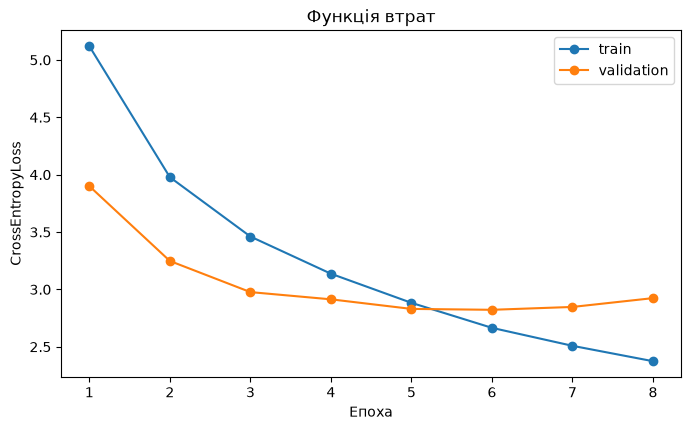

In [10]:
epochs = range(1, len(history['train']) + 1)
plt.figure(figsize=(8, 4.5))
plt.plot(epochs, history['train'], 'o-', label='train')
plt.plot(epochs, history['val'], 'o-', label='validation')
plt.xlabel('Епоха')
plt.ylabel('CrossEntropyLoss')
plt.title('Функція втрат')
plt.legend()
plt.show()

Втрати на навчальних даних падають усі 8 епох, з 5.12 до 2.37. Втрати на валідації падають до 6 епохи (2.82), а потім починають рости і на 8 епосі доходять до 2.92. Це ознака перенавчання: після 6 епохи модель краще запам'ятовує навчальні речення, але на нових не покращується. Тому я залишаю модель з 6 епохи.

У перших епохах втрати на валідації навіть нижчі, ніж на навчанні. Причина в тому, що на валідації модель завжди отримує правильні попередні слова, а під час навчання лише в половині випадків. Значення втрат у межах орієнтиру із завдання (від 2 до 4).

### 7.2 Механізм уваги

Функція translate перекладає речення слово за словом: на кожному кроці бере найімовірніше слово і запам'ятовує ваги уваги. На карті уваги по горизонталі слова німецького речення, по вертикалі слова перекладу. Чим темніша клітинка, тим більше уваги модель приділила цьому німецькому слову, коли писала англійське.

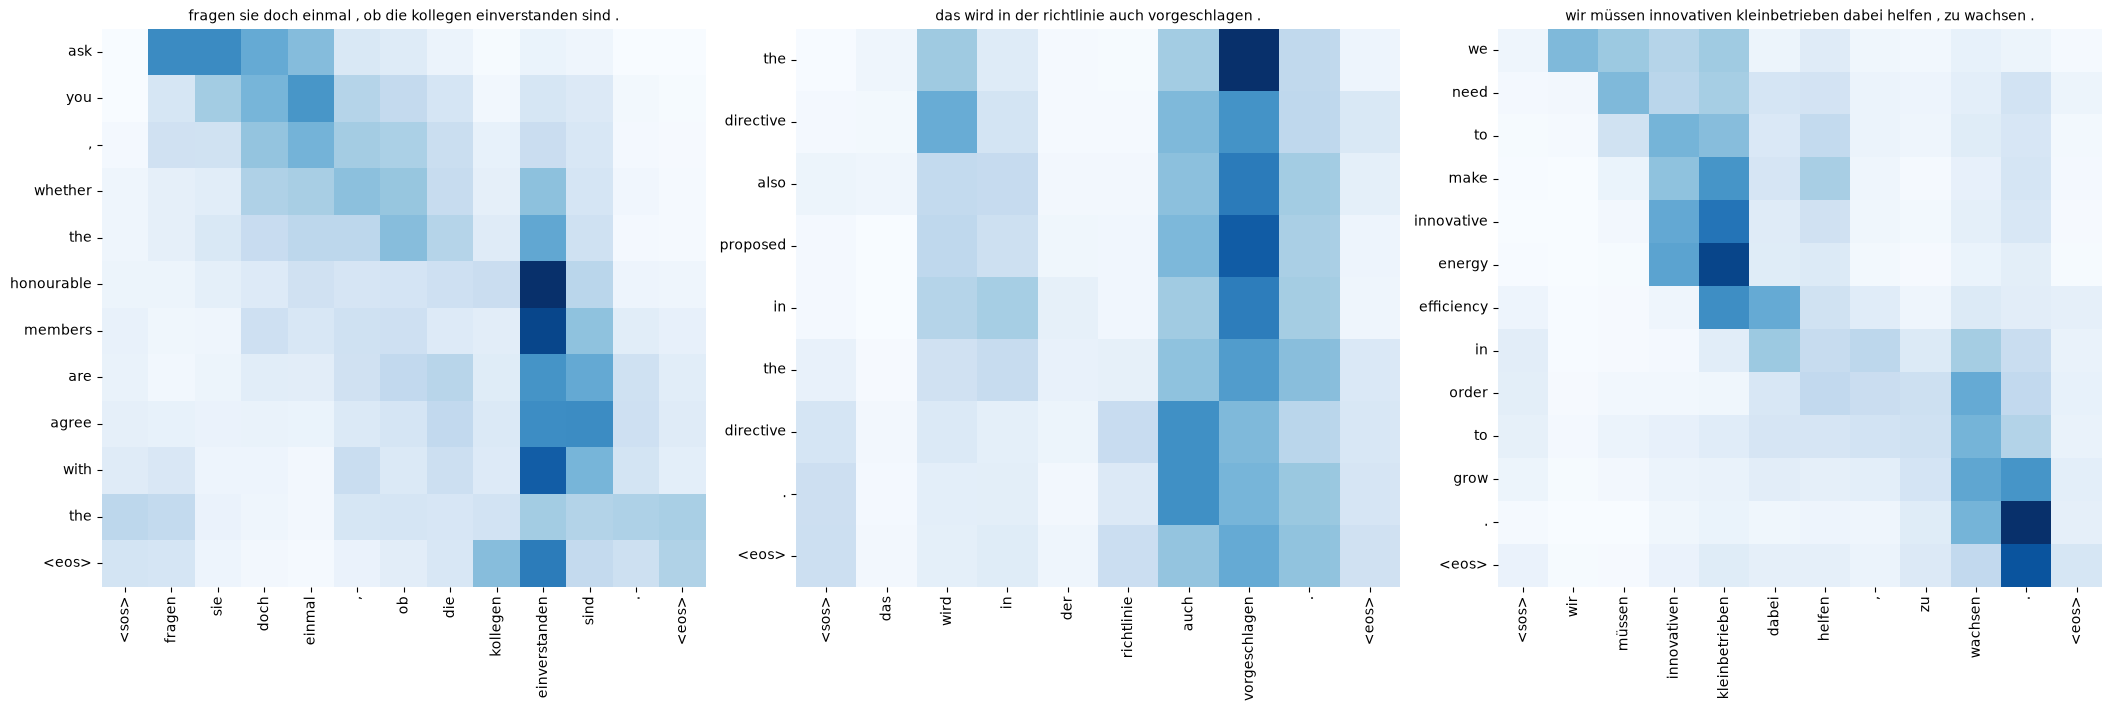

de:  fragen sie doch einmal , ob die kollegen einverstanden sind .
en:  at least ask whether the members agree with that decision .
мод: ask you , whether the honourable members are agree with the

de:  das wird in der richtlinie auch vorgeschlagen .
en:  this is also proposed in the directive .
мод: the directive also proposed in the directive .

de:  wir müssen innovativen kleinbetrieben dabei helfen , zu wachsen .
en:  we must take innovative small businesses and help them grow .
мод: we need to make innovative energy efficiency in order to grow .



In [11]:
def translate(src_tokens, max_len=30):
    model.eval()
    src = torch.tensor(src_vocab.encode(src_tokens)).unsqueeze(1).to(DEVICE)
    with torch.no_grad():
        encoder_outputs, hidden = model.encoder(src)
        mask = (src != PAD_IDX).T
        token, out_ids, attentions = torch.tensor([SOS_IDX], device=DEVICE), [], []
        for _ in range(max_len):
            prediction, hidden, a = model.decoder(token, hidden, encoder_outputs, mask)
            token = prediction.argmax(1)
            attentions.append(a.squeeze(0).cpu().numpy())
            if token.item() == EOS_IDX:
                break
            out_ids.append(token.item())
    return [trg_vocab.itos[i] for i in out_ids], np.array(attentions)


def show_attention(src_tokens, out_tokens, attention, ax):
    y_labels = out_tokens + ['<eos>'] if len(attention) > len(out_tokens) else out_tokens
    sns.heatmap(attention, ax=ax, cmap='Blues', cbar=False,
                xticklabels=['<sos>'] + src_tokens + ['<eos>'], yticklabels=y_labels)
    ax.tick_params(axis='x', rotation=90)
    ax.tick_params(axis='y', rotation=0)


test_src, test_trg = data['test']
examples = [i for i in range(len(test_src)) if 7 <= len(test_src[i]) <= 12][:3]
fig, axes = plt.subplots(1, 3, figsize=(21, 7), layout='constrained')
for ax, i in zip(axes, examples):
    out_tokens, attention = translate(test_src[i])
    show_attention(test_src[i], out_tokens, attention, ax)
    ax.set_title(' '.join(test_src[i]), fontsize=10)
plt.show()
for i in examples:
    print('de: ', ' '.join(test_src[i]))
    print('en: ', ' '.join(test_trg[i]))
    print('мод:', ' '.join(translate(test_src[i])[0]))
    print()

Що видно на картах уваги:
- у третьому прикладі увага йде майже по діагоналі: we дивиться на wir, innovative на innovativen, grow на wachsen. Порядок слів тут у двох мовах схожий;
- у німецькій дієслово часто стоїть у кінці речення, і модель його знаходить: у першому прикладі agree дивиться на einverstanden, у другому proposed на vorgeschlagen;
- коли модель не знає рідкісного слова, вона дивиться на правильне місце, але пише не те: на kleinbetrieben (малі підприємства) вона пише energy efficiency;
- у другому прикладі увага розмита і майже весь час тримається на vorgeschlagen, тому модель двічі пише the directive.

Отже, увага допомагає декодеру знаходити потрібне слово навіть далеко в реченні. Помилки здебільшого пов'язані з рідкісними словами і розмитою увагою.

## 8. Приклади перекладу

Перекладаю кілька тестових речень, яких модель не бачила під час навчання, і порівнюю з еталонним перекладом з набору даних.

In [12]:
pd.set_option('display.max_colwidth', None)
rows = [{'німецькою': ' '.join(test_src[i]), 'еталон': ' '.join(test_trg[i]),
         'переклад моделі': ' '.join(translate(test_src[i])[0])} for i in range(3, 13)]
pd.DataFrame(rows)

,німецькою,еталон,переклад моделі
0,"diese allerdings wollen sie um 8 % erhöhen , wobei die forschungsausgaben mehr als 60 % der kategorie 3 ausmachen .","nevertheless , you want to increase this expenditure by 8 % and research expenditure accounts for over 60 % of category 3 .","that would , however , to to increase % % deficit , more than 60 % of 3 % 3 . 3 ."
1,"die kommission nutzt jede gelegenheit , um den betroffenen parteien ihren standpunkt deutlich zu machen .",the commission takes every opportunity to reiterate its position to the interested parties .,the commission uses every opportunity to make the to the the of the parties concerned .
2,"wenn sie aufgrund einer fehleinschätzung der regierungen der mitgliedstaaten entstanden sind , ist die kürzung berechtigt .","if they have come about through miscalculations on the part of member states ' governments , then cutting them is justified .","if they have to be the member of governments of the member states , the reduction in the ."
3,"fragen sie doch einmal , ob die kollegen einverstanden sind .",at least ask whether the members agree with that decision .,"ask you , whether the honourable members are agree with the"
4,das wird in der richtlinie auch vorgeschlagen .,this is also proposed in the directive .,the directive also proposed in the directive .
5,"ich weiß , dass es sehr teuer ist , aber ich wäre dennoch dafür , dass wir zu seinen gunsten opfer bringen .","i know that it is very expensive , but i would nevertheless like us to make sacrifices for its sake .","i know that it is very expensive , but i would be for that we are giving it for his report ."
6,"wir müssen innovativen kleinbetrieben dabei helfen , zu wachsen .",we must take innovative small businesses and help them grow .,we need to make innovative energy efficiency in order to grow .
7,der zweite schritt ist die änderung der verträge .,the second step is the amendment of the treaties .,the second step is the the of the treaties .
8,"sanktionen sind ein weiteres mittel , das uns zum schutz der menschenrechte weltweit zur verfügung steht .",sanctions are a further means at our disposal for protecting human rights around the world .,sanctions are a further means that we have to the protection of the world world .
9,. – herr präsident ! ich möchte der berichterstatterin gratulieren und ihr für diesen bericht danken .,"mr president , i wish to congratulate the rapporteur and also thank her for this report .","mr president , i should like to congratulate the rapporteur and for her report ."


Модель добре перекладає початок речень і типові для парламенту фрази: mr president , i should like to congratulate the rapporteur; i know that it is very expensive; sanctions are a further means.

Слабкі місця:
- у довгих реченнях кінець перекладу часто ламається, з'являються зайві або повторені слова (the the, world world);
- рідкісні слова модель перекладає неправильно або пропускає, наприклад kleinbetrieben і fehleinschätzung;
- числа і відсотки плутаються.

## 9. Аналіз і висновки

- Модель seq2seq з двонаправленим GRU-енкодером, механізмом уваги і GRU-декодером навчилася перекладати з німецької на англійську. Найкращі втрати на валідації 2.82 (perplexity 16.8) після 6 епох, навчання тривало близько 55 хвилин.
- Механізм уваги працює: на картах видно, що декодер знаходить відповідне німецьке слово, зокрема дієслово в кінці речення.
- Сильні сторони: проста архітектура, швидке навчання на 100 тисячах речень, добрі переклади коротких типових фраз.
- Слабкі сторони: помилки в рідкісних словах і довгих реченнях, повтори слів, перенавчання після 6 епохи.

Що можна покращити:
- взяти більше даних і більший словник, щоб модель знала більше рідкісних слів;
- розбивати слова на частини (наприклад, методом BPE), щоб рідкісні слова не ставали невідомими;
- замість вибору найімовірнішого слова на кожному кроці використати beam search;
- спробувати Transformer, який зазвичай перекладає краще.